In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from PIL import Image

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
dataset_path = "/kaggle/input/datasets/karakaggle/kaggle-cat-vs-dog-dataset/kagglecatsanddogs_3367a/PetImages"

# Check whether the directory exists
if os.path.exists(dataset_path):
    print("Dataset path exists!")
else:
    print("Dataset path does not exist!")

# Display folders
folders = os.listdir(dataset_path)

print("\nFolders in dataset:")

for folder in folders:
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):
        print(folder)

Dataset path exists!

Folders in dataset:
Cat
Dog


In [3]:
cat_path = os.path.join(dataset_path, "Cat")
dog_path = os.path.join(dataset_path, "Dog")

cat_images = os.listdir(cat_path)
dog_images = os.listdir(dog_path)

print("Total Cat images:", len(cat_images))
print("Total Dog images:", len(dog_images))

print("\nTotal images:", len(cat_images) + len(dog_images))

Total Cat images: 12491
Total Dog images: 12470

Total images: 24961


In [4]:
print("Sample Cat filenames:")
print(cat_images[:10])

print("\nSample Dog filenames:")
print(dog_images[:10])

Sample Cat filenames:
['0.jpg', '1.jpg', '10.jpg', '100.jpg', '1000.jpg', '10000.jpg', '10001.jpg', '10002.jpg', '10003.jpg', '10004.jpg']

Sample Dog filenames:
['0.jpg', '1.jpg', '10.jpg', '100.jpg', '1000.jpg', '10000.jpg', '10001.jpg', '10002.jpg', '10003.jpg', '10004.jpg']


In [5]:
# Select one image from each class
cat_sample = os.path.join(cat_path, cat_images[0])
dog_sample = os.path.join(dog_path, dog_images[0])

# Open images
cat_img = Image.open(cat_sample)
dog_img = Image.open(dog_sample)

# Display image properties
print("CAT IMAGE")
print("Dimensions:", cat_img.size)
print("Format:", cat_img.format)
print("Mode:", cat_img.mode)

print("\nDOG IMAGE")
print("Dimensions:", dog_img.size)
print("Format:", dog_img.format)
print("Mode:", dog_img.mode)

CAT IMAGE
Dimensions: (500, 375)
Format: JPEG
Mode: RGB

DOG IMAGE
Dimensions: (500, 375)
Format: JPEG
Mode: RGB


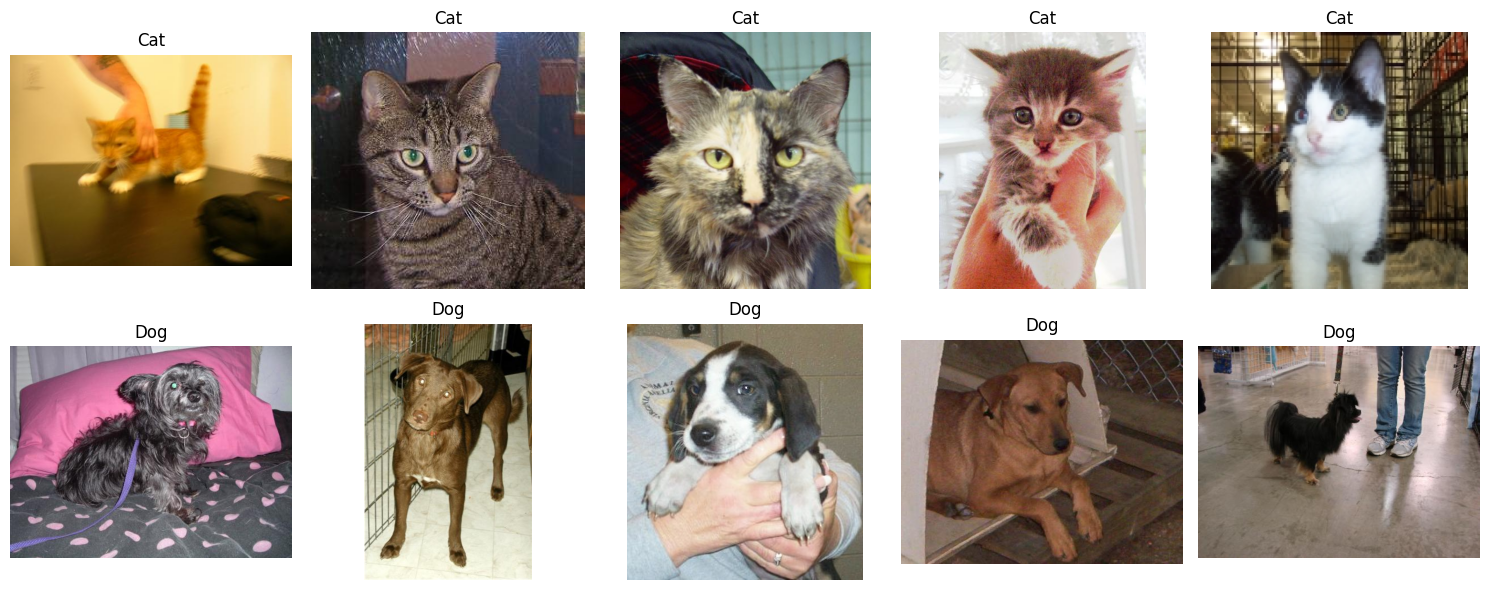

In [6]:
plt.figure(figsize=(15, 6))

# Display 5 Cat images
for i in range(5):
    img_path = os.path.join(cat_path, cat_images[i])
    img = Image.open(img_path)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title("Cat")
    plt.axis("off")

# Display 5 Dog images
for i in range(5):
    img_path = os.path.join(dog_path, dog_images[i])
    img = Image.open(img_path)

    plt.subplot(2, 5, i + 6)
    plt.imshow(img)
    plt.title("Dog")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
corrupted_images = []

for folder in ["Cat", "Dog"]:

    folder_path = os.path.join(dataset_path, folder)

    for filename in os.listdir(folder_path):

        image_path = os.path.join(folder_path, filename)

        try:
            with Image.open(image_path) as img:
                img.verify()

        except Exception:
            corrupted_images.append(image_path)

print("Total corrupted images:", len(corrupted_images))
print("Total valid images:", 24961 - len(corrupted_images))

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Total corrupted images: 2
Total valid images: 24959


In [8]:
valid_image_paths = []
valid_labels = []

for folder, label in [("Cat", 0), ("Dog", 1)]:

    folder_path = os.path.join(dataset_path, folder)

    for filename in os.listdir(folder_path):

        image_path = os.path.join(folder_path, filename)

        try:
            with Image.open(image_path) as img:
                img.verify()

            valid_image_paths.append(image_path)
            valid_labels.append(label)

        except Exception:
            pass

print("Total valid images:", len(valid_image_paths))
print("Total Cat images:", valid_labels.count(0))
print("Total Dog images:", valid_labels.count(1))

Total valid images: 24959
Total Cat images: 12490
Total Dog images: 12469


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    valid_image_paths,
    valid_labels,
    test_size=0.2,
    random_state=42,
    stratify=valid_labels
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 19967
Testing images: 4992


In [10]:
IMG_SIZE = 128
BATCH_SIZE = 32

print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(X_train) // BATCH_SIZE)
print("Testing batches:", len(X_test) // BATCH_SIZE)

Image size: 128 x 128
Batch size: 32
Training batches: 623
Testing batches: 156


In [11]:
def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image = image.resize((IMG_SIZE, IMG_SIZE))

    image = np.array(image, dtype=np.float32)
    image = image / 255.0

    return image

print("Image preprocessing function created successfully!")

Image preprocessing function created successfully!


Image shape: (128, 128, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.8901961


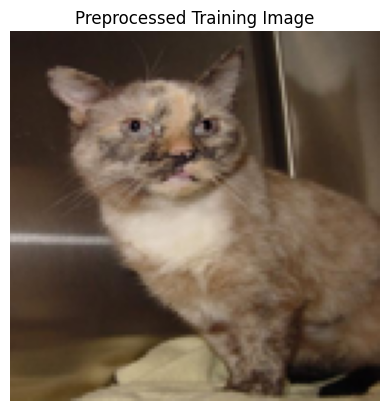

In [12]:
sample_image = preprocess_image(X_train[0])

print("Image shape:", sample_image.shape)
print("Minimum pixel value:", sample_image.min())
print("Maximum pixel value:", sample_image.max())

plt.imshow(sample_image)
plt.title("Preprocessed Training Image")
plt.axis("off")
plt.show()

In [13]:
def load_image(image_path, label):
    image = tf.numpy_function(
        preprocess_image,
        [image_path],
        tf.float32
    )

    image.set_shape((IMG_SIZE, IMG_SIZE, 3))

    return image, label


train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

train_dataset = (
    train_dataset
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    test_dataset
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and testing TensorFlow datasets created successfully!")

Training and testing TensorFlow datasets created successfully!


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Images batch shape: (32, 128, 128, 3)
Labels batch shape: (32,)
Image minimum value: 0.0
Image maximum value: 1.0
Sample labels: [0 0 0 0 1 0 1 1 1 0]


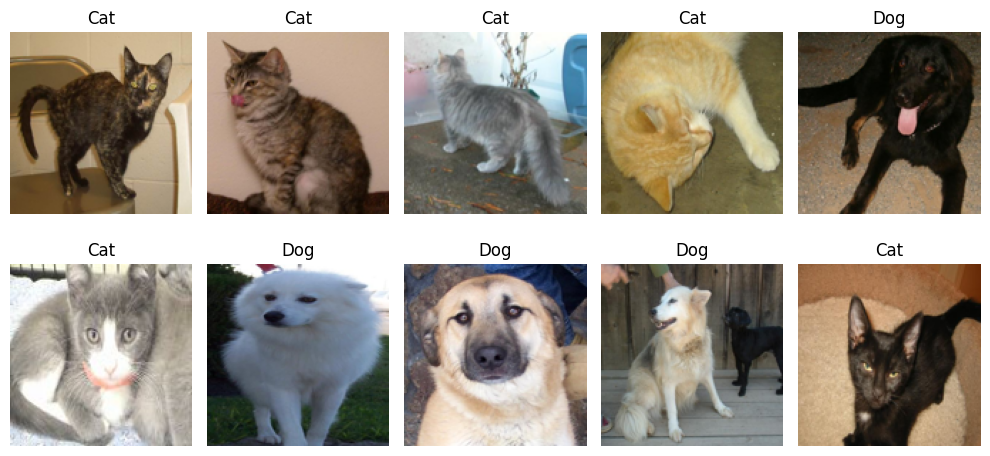

In [14]:
for images, labels in train_dataset.take(1):

    print("Images batch shape:", images.shape)
    print("Labels batch shape:", labels.shape)

    print("Image minimum value:", tf.reduce_min(images).numpy())
    print("Image maximum value:", tf.reduce_max(images).numpy())

    print("Sample labels:", labels[:10].numpy())

    plt.figure(figsize=(10, 5))

    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy())
        plt.title("Cat" if labels[i].numpy() == 0 else "Dog")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # First convolution block
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Second convolution block
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Third convolution block
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Classification layers
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),

    # Binary classification output
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [17]:
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=10
)

Epoch 1/10
624/624 ━━━━━━━━━━━━━━━━━━━━ 185s 282ms/step - accuracy: 0.6527 - loss: 0.6214 - val_accuracy: 0.7196 - val_loss: 0.5549
Epoch 2/10
624/624 ━━━━━━━━━━━━━━━━━━━━ 48s 75ms/step - accuracy: 0.7582 - loss: 0.5001 - val_accuracy: 0.7680 - val_loss: 0.4805
Epoch 3/10
624/624 ━━━━━━━━━━━━━━━━━━━━ 48s 74ms/step - accuracy: 0.8088 - loss: 0.4191 - val_accuracy: 0.7883 - val_loss: 0.4427
Epoch 4/10
624/624 ━━━━━━━━━━━━━━━━━━━━ 49s 75ms/step - accuracy: 0.8408 - loss: 0.3614 - val_accuracy: 0.8219 - val_loss: 0.4039
Epoch 5/10
624/624 ━━━━━━━━━━━━━━━━━━━━ 50s 77ms/step - accuracy: 0.8677 - loss: 0.3027 - val_accuracy: 0.8299 - val_loss: 0.3903
Epoch 6/10
624/624 ━━━━━━━━━━━━━━━━━━━━ 49s 75ms/step - accuracy: 0.8953 - loss: 0.2516 - val_accuracy: 0.8409 - val_loss: 0.3917
Epoch 7/10
624/624 ━━━━━━━━━━━━━━━━━━━━ 49s 75ms/step - accuracy: 0.9224 - loss: 0.1978 - val_accuracy: 0.8442 - val_loss: 0.4221
Epoch 8/10
624/624 ━━━━━━━━━━━━━━━━━━━━ 49s 76ms/step - accuracy: 0.9333 - loss: 0.1647 

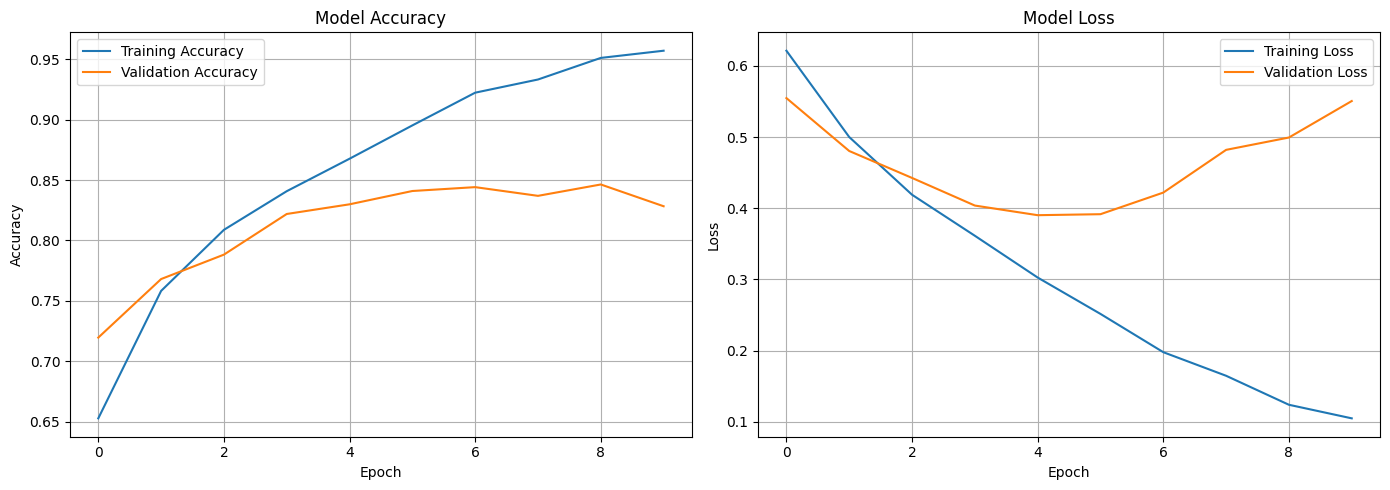

In [18]:
plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()